Задача 1: Катер с разряжающейся батареей

In [ ]:
import sympy as sp

In [ ]:
# Объявляем переменные и параметры
t = sp.symbols('t', real=True)
m, k, P0, tau, v0 = sp.symbols(
    'm k P0 tau v0', positive=True
)


In [ ]:
v = sp.Function('v')(t)

In [ ]:
# Исходное дифференциальное уравнение
ode = sp.Eq(
    m * sp.diff(v, t),
    P0 * sp.exp(-t / tau) / v - k * v
)

In [ ]:
print("Исходное уравнение:")
sp.pprint(ode)

Исходное уравнение:
                 -t          
                 ───         
                  τ          
  d          P₀⋅ℯ            
m⋅──(v(t)) = ─────── - k⋅v(t)
  dt          v(t)           


In [ ]:
# Приводим уравнение к виду Бернулли
bernoulli = sp.Eq(
    sp.diff(v, t) + k/m * v,
    P0/m * sp.exp(-t/tau) * v**(-1)
)

In [ ]:
print("\nУравнение Бернулли:")
sp.pprint(bernoulli)


Уравнение Бернулли:
                        -t 
                        ───
                         τ 
k⋅v(t)   d          P₀⋅ℯ   
────── + ──(v(t)) = ───────
  m      dt         m⋅v(t) 


In [ ]:
print("\np(t) =")
sp.pprint(k/m)


p(t) =
k
─
m


In [ ]:
print("\nq(t) =")
sp.pprint(P0/m * sp.exp(-t/tau))

print("\nn = -1")



q(t) =
    -t 
    ───
     τ 
P₀⋅ℯ   
───────
   m   

n = -1


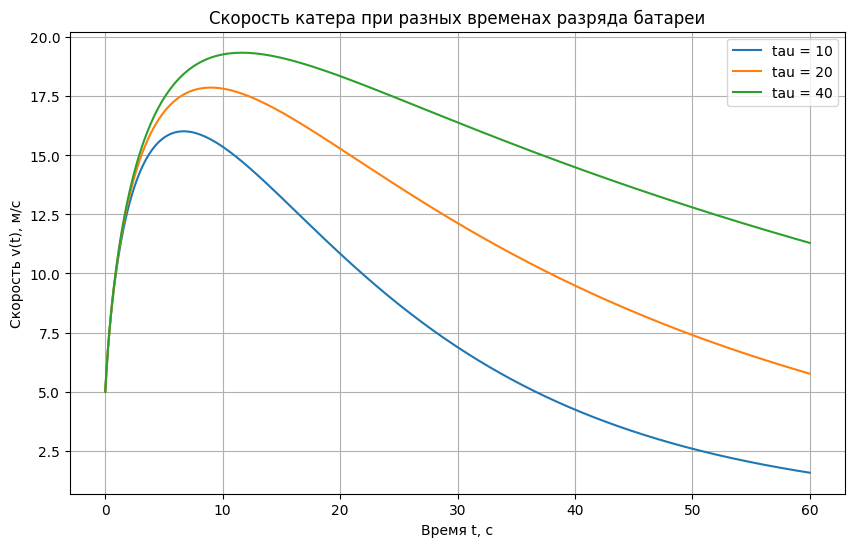

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Исходные параметры
mass = 1000
k_value = 100
P0_value = 50000
v0_value = 5

# Разные времена разряда батареи
tau_values = [10, 20, 40]

# Время от 0 до 60 секунд
time = np.linspace(0, 60, 500)

plt.figure(figsize=(10, 6))

for tau_value in tau_values:
    a = 2 * k_value / mass
    b = 1 / tau_value

    # Решение для квадрата скорости
    u_values = (
        v0_value**2 * np.exp(-a * time)
        + (2 * P0_value / mass)
        * (np.exp(-b * time) - np.exp(-a * time))
        / (a - b)
    )

    # Скорость — положительный квадратный корень
    v_values = np.sqrt(np.maximum(u_values, 0))

    plt.plot(
        time,
        v_values,
        label=f"tau = {tau_value}"
    )

plt.xlabel("Время t, с")
plt.ylabel("Скорость v(t), м/с")
plt.title("Скорость катера при разных временах разряда батареи")
plt.grid(True)
plt.legend()
plt.show()


Задача 2: Популяция в линейно ухудшающей среде

In [ ]:
import sympy as sp

In [ ]:
t = sp.symbols('t', real=True)
a, b, c, N0 = sp.symbols('a b c N0', positive=True)

In [ ]:
N = sp.Function('N')(t)

In [ ]:
# Исходное уравнение
ode = sp.Eq(
    sp.diff(N, t),
    (a - b*t)*N - c*N**2
)

In [ ]:
print("Исходное уравнение:")
sp.pprint(ode)

Исходное уравнение:
d               2                    
──(N(t)) = - c⋅N (t) + (a - b⋅t)⋅N(t)
dt                                   


In [ ]:
# Канонический вид уравнения Бернулли
bernoulli = sp.Eq(
    sp.diff(N, t) + (b*t - a)*N,
    -c*N**2
)

In [ ]:
print("\nКанонический вид:")
sp.pprint(bernoulli)


Канонический вид:
                  d              2   
(-a + b⋅t)⋅N(t) + ──(N(t)) = -c⋅N (t)
                  dt                 


In [ ]:
print("\nP(t) =")
sp.pprint(b*t - a)


P(t) =
-a + b⋅t


In [ ]:
print("\nQ(t) =")
sp.pprint(-c)
print("\nn = 2")


Q(t) =
-c

n = 2


In [ ]:
# Замена z = 1/N
z = sp.Function('z')(t)

ode_z = sp.Eq(
    sp.diff(z, t) + (a - b*t)*z,
    c
)

In [ ]:
# Решаем с начальным условием N(0) = N0,
# то есть z(0) = 1/N0
solution_z = sp.dsolve(
    ode_z,
    ics={z.subs(t, 0): 1/N0}
)


In [ ]:
print("\nРешение z(t):")
sp.pprint(solution_z)


Решение z(t):
       ⎛          2                ⎞                           2             2 ↪
       ⎜         a                 ⎟                          a           b⋅t  ↪
       ⎜         ───               ⎟                          ─── - a⋅t + ──── ↪
       ⎜         2⋅b    ⎛√2⋅a⎞     ⎟    ⎛     b⋅t⎞            2⋅b          2   ↪
       ⎜√2⋅√π⋅c⋅ℯ   ⋅erf⎜────⎟     ⎟  t⋅⎜-a + ───⎟   √2⋅√π⋅c⋅ℯ                 ↪
       ⎜                ⎝2⋅√b⎠   1 ⎟    ⎝      2 ⎠                             ↪
z(t) = ⎜────────────────────── + ──⎟⋅ℯ             - ───────────────────────── ↪
       ⎝         2⋅√b            N₀⎠                                     2⋅√b  ↪

↪                     
↪     ⎛   ⎛a        ⎞⎞
↪     ⎜√2⋅⎜── - √b⋅t⎟⎟
↪     ⎜   ⎝√b       ⎠⎟
↪ ⋅erf⎜──────────────⎟
↪     ⎝      2       ⎠
↪ ────────────────────
↪                     


In [ ]:
# Возвращаемся к N(t) = 1/z(t)
solution_N = sp.simplify(1 / solution_z.rhs)

In [ ]:
print("\nРешение N(t):")
sp.pprint(solution_N)


Решение N(t):
                                   ⎛    b⋅t⎞                        
                                 t⋅⎜a - ───⎟                        
                                   ⎝     2 ⎠                        
                        2⋅N₀⋅√b⋅ℯ                                   
────────────────────────────────────────────────────────────────────
             2                           2                          
            a                           a                           
            ───                         ───                         
            2⋅b    ⎛√2⋅a⎞               2⋅b    ⎛√2⋅(a - b⋅t)⎞       
√2⋅√π⋅N₀⋅c⋅ℯ   ⋅erf⎜────⎟ - √2⋅√π⋅N₀⋅c⋅ℯ   ⋅erf⎜────────────⎟ + 2⋅√b
                   ⎝2⋅√b⎠                      ⎝    2⋅√b    ⎠       


In [ ]:
print("\nПроверка N(0) = N0:")
sp.pprint(sp.simplify(solution_N.subs(t, 0)))


Проверка N(0) = N0:
N₀


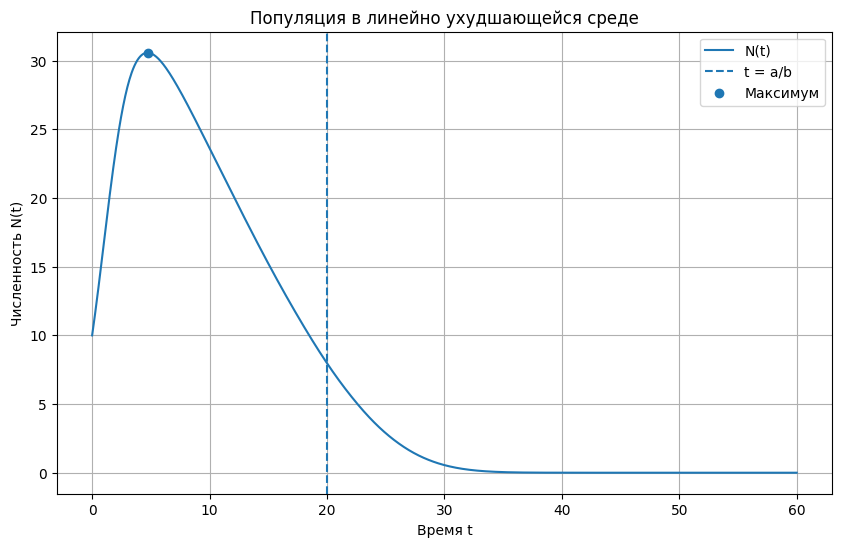

Время пика: 4.745
Максимальная численность: 30.58
Момент a/b: 20.0


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

a = 0.8
b = 0.04
c = 0.02
N0 = 10

def dN_dt(t, N):
    return (a - b*t)*N - c*N**2

# Интервал времени
t = np.linspace(0, 60, 1000)

solution = solve_ivp(
    dN_dt, (0, 60), [N0], t_eval=t
)

N = solution.y[0]

# Находим максимум
peak_index = np.argmax(N)
t_peak = t[peak_index]
N_peak = N[peak_index]

# Строим график
plt.figure(figsize=(10, 6))
plt.plot(t, N, label="N(t)")
plt.axvline(a/b, linestyle="--", label="t = a/b")
plt.scatter(t_peak, N_peak, label="Максимум")

plt.xlabel("Время t")
plt.ylabel("Численность N(t)")
plt.title("Популяция в линейно ухудшающейся среде")
plt.grid(True)
plt.legend()
plt.show()

print("Время пика:", round(t_peak, 3))
print("Максимальная численность:", round(N_peak, 3))
print("Момент a/b:", round(a/b, 3))
